In [6]:
import numpy as np
import pandas as pd

In [7]:
# from sklearn.datasets import fetch_california_housing
# housing = fetch_california_housing()
# print(housing.data.shape, housing.target.shape)
# print(housing.feature_names[0:6])

In [8]:
# housing = fetch_california_housing(as_frame=True)
# df = housing.frame

# df.to_csv("california_housing.csv", index=False)

In [9]:
df=pd.read_csv("california_housing.csv")

In [10]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [11]:
# making the column names consistent
df.columns = (
    df.columns
    .str.replace(r"(?<!^)(?=[A-Z])", "_", regex=True)
    .str.lower()
)

In [12]:
df.head()

,med_inc,house_age,ave_rooms,ave_bedrms,population,ave_occup,latitude,longitude,med_house_val
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [13]:
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()

med_inc
[8.3252 8.3014 7.2574 5.6431 3.8462]
12928

house_age
[41. 21. 52. 42. 50.]
52

ave_rooms
[6.98412698 6.23813708 8.28813559 5.8173516  6.28185328]
19392

ave_bedrms
[1.02380952 0.97188049 1.07344633 1.07305936 1.08108108]
14233

population
[ 322. 2401.  496.  558.  565.]
3888

ave_occup
[2.55555556 2.10984183 2.80225989 2.54794521 2.18146718]
18841

latitude
[37.88 37.86 37.85 37.84 37.83]
862

longitude
[-122.23 -122.22 -122.24 -122.25 -122.26]
844

med_house_val
[4.526 3.585 3.521 3.413 3.422]
3842



EXPLORATORY DATA ANALYSIS

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

<Axes: xlabel='med_house_val', ylabel='Count'>

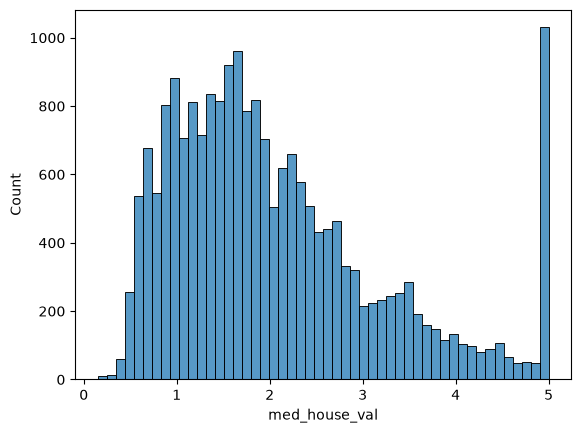

In [15]:
sns.histplot(df.med_house_val,bins=50)

In [ ]:
# Removing the  long tail with logarithm
np.log([0 + 1, 1 + 1, 10 + 1, 1000 + 1, 100000 + 1])

array([ 0.        ,  0.69314718,  2.39789527,  6.90875478, 11.51293546])

In [17]:
np.log1p([0, 1, 10, 1000, 100000])

array([ 0.        ,  0.69314718,  2.39789527,  6.90875478, 11.51293546])

In [18]:
house_prices = np.log1p(df.med_house_val)

<Axes: xlabel='med_house_val', ylabel='Count'>

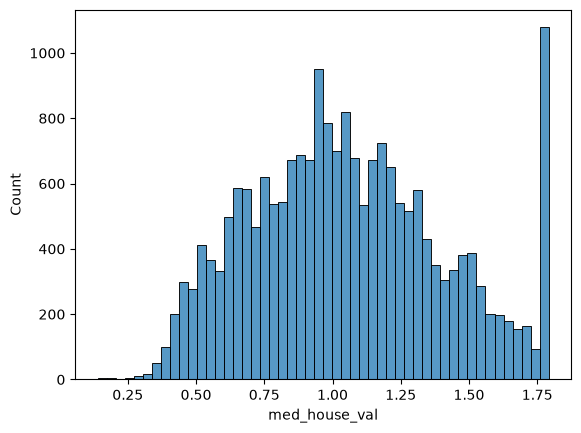

In [19]:
sns.histplot(house_prices,bins=50)

In [20]:
# checking for missing values
df.isnull().sum()

med_inc          0
house_age        0
ave_rooms        0
ave_bedrms       0
population       0
ave_occup        0
latitude         0
longitude        0
med_house_val    0
dtype: int64

VALIDATING THE FRAMEWORK

In [21]:
n = len(df)

n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

In [22]:
n,n_val,n_test,n_train

(20640, 4128, 4128, 12384)

In [23]:
# taking part of the dataframe using iloc
df.iloc[:10]

,med_inc,house_age,ave_rooms,ave_bedrms,population,ave_occup,latitude,longitude,med_house_val
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
5,4.0368,52.0,4.761658,1.103627,413.0,2.139896,37.85,-122.25,2.697
6,3.6591,52.0,4.931907,0.951362,1094.0,2.128405,37.84,-122.25,2.992
7,3.1200,52.0,4.797527,1.061824,1157.0,1.788253,37.84,-122.25,2.414
8,2.0804,42.0,4.294118,1.117647,1206.0,2.026891,37.84,-122.26,2.267
9,3.6912,52.0,4.970588,0.990196,1551.0,2.172269,37.84,-122.25,2.611


In [24]:
df_val=df.iloc[:n_val]
df_test=df.iloc[n_val:n_val+n_test]
df_train=df.iloc[n_val+n_test:]

In [25]:
idx = np.arange(n)
np.random.shuffle(idx)

In [26]:
df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train+n_val]]
df_test = df.iloc[idx[n_train+n_val:]]

In [27]:
np.random.seed(2)

idx = np.arange(n)
np.random.shuffle(idx)

In [28]:
len(df_train), len(df_val), len(df_test)

(12384, 4128, 4128)

In [29]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [30]:
df_train

,med_inc,house_age,ave_rooms,ave_bedrms,population,ave_occup,latitude,longitude,med_house_val
0,2.1281,33.0,3.834218,1.051724,1607.0,2.131300,32.63,-117.08,1.398
1,5.0653,35.0,5.602837,0.943262,926.0,3.283688,33.93,-118.31,1.580
2,5.0662,46.0,6.224057,1.056604,938.0,2.212264,37.30,-121.89,3.316
3,2.9830,45.0,5.633065,1.020161,555.0,2.237903,37.72,-122.14,2.027
4,3.9243,44.0,4.276442,1.008413,1779.0,2.138221,37.42,-122.15,4.048
...,...,...,...,...,...,...,...,...,...
12379,5.3674,26.0,6.875723,0.971098,988.0,2.855491,33.65,-117.97,3.393
12380,3.7315,20.0,7.368304,1.738839,1085.0,2.421875,37.58,-118.74,1.593
12381,5.5701,34.0,7.170616,1.094787,545.0,2.582938,37.76,-122.14,2.528
12382,1.6200,19.0,3.283525,1.010217,1205.0,1.538953,32.64,-117.09,1.313


In [31]:
# preparing y and med_house_val
y_train = np.log1p(df_train.med_house_val)
y_val = np.log1p(df_val.med_house_val)
y_test = np.log1p(df_test.med_house_val)

In [32]:
del df_train['med_house_val']
del df_val['med_house_val']
del df_test['med_house_val']